# Getting Started with LightKurve

I'm exploring the analysis of TESS data, particularly looking at the identification of exoplanets in TESS (Transiting Exoplanet Survey Satellite) data using the data it has captured over time. Let's give it a go.



In [1]:
from lightkurve import search_targetpixelfile
pixelfile = search_targetpixelfile('KIC 8462852', quarter=16).download(quality_bitmask='hardest')

c:\Users\mark-\Documents\Repositories\astro-data-lab\.venv\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


<Axes: title={'center': 'Target ID: 8462852, Cadence: 66823'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>

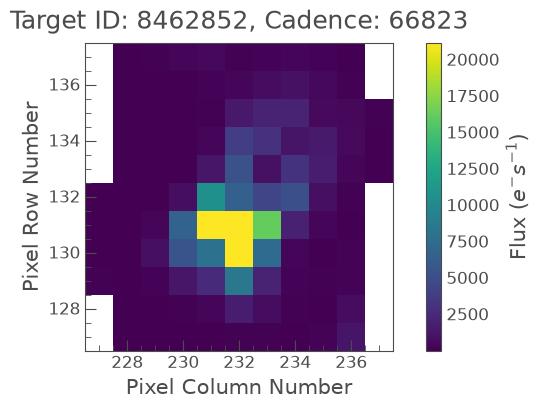

In [2]:
pixelfile.plot(frame=100)

In [3]:
lc = pixelfile.to_lightcurve(aperture_mask='all')

In [4]:
lc

time,flux,flux_err,centroid_col,centroid_row,cadenceno,quality
,electron / s,electron / s,pix,pix,,
Time,float32,float32,float64,float64,int32,int32
1472.1177793449679,258645.03125,18.723051071166992,231.9673225173918,131.14635857005212,66713,0
1472.1382122338982,258660.046875,18.72334861755371,231.9671381956879,131.1455329599996,66714,0
1472.1586449230672,258690.078125,18.723417282104492,231.96697751093495,131.14547901637522,66715,0
1472.1790778124705,258683.328125,18.72397232055664,231.96678360583206,131.14500604059887,66716,0
1472.1995106019822,258655.40625,18.723506927490234,231.96657673426097,131.14489915411463,66717,0
1472.2199432917332,258663.15625,18.723569869995117,231.96699753628025,131.14502413754656,66718,0
1472.2403761816604,258686.71875,18.724145889282227,231.96669495657952,131.14451785560516,66719,0
1472.2608089718124,258663.28125,18.724172592163086,231.96668273644525,131.14450988662415,66720,0


In [5]:
lc.time, lc.flux

(<Time object: scale='tdb' format='bkjd' value=[1472.11777934 1472.13821223 1472.15864492 ... 1557.89718798 1557.9380561
  1557.95849016]>,
 <Quantity [258645.03, 258660.05, 258690.08, ..., 258929.86, 258884.66,
            258865.6 ] electron / s>)

<Axes: xlabel='Time - 2454833 [BKJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

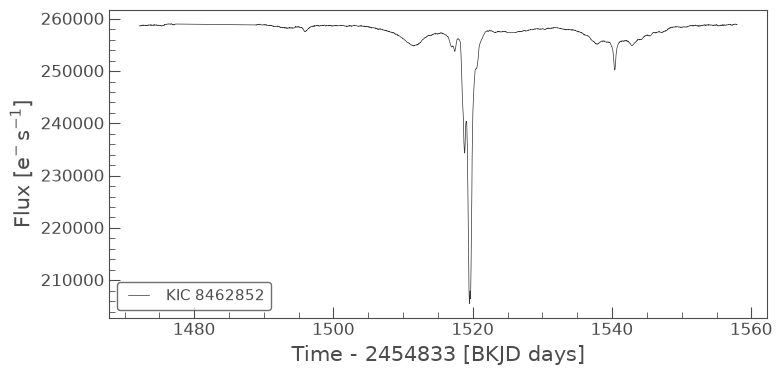

In [6]:
%matplotlib inline

lc.plot()

In [7]:

pixelfile = search_targetpixelfile('KIC 6922244', quarter=4).download()
lc = pixelfile.to_lightcurve(aperture_mask=pixelfile.pipeline_mask)

c:\Users\mark-\Documents\Repositories\astro-data-lab\.venv\Lib\site-packages\lightkurve\search.py:421: LightkurveWarning: Warning: 4 files available to download. Only the first file has been downloaded. Please use `download_all()` or specify additional criteria (e.g. quarter, campaign, or sector) to limit your search.
  warnings.warn(


<Axes: xlabel='Time - 2454833 [BKJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

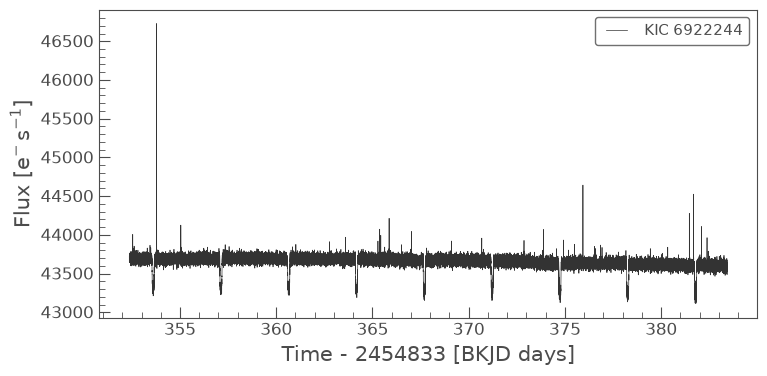

In [8]:
%matplotlib inline

lc.plot()

# Flattening

<Axes: xlabel='Time - 2454833 [BKJD days]', ylabel='Normalized Flux'>

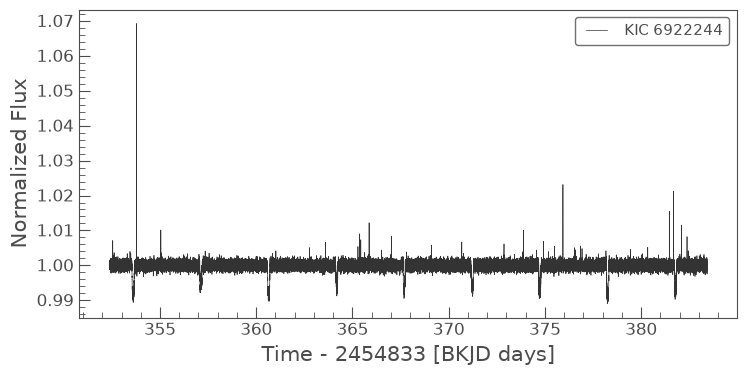

In [9]:
%matplotlib inline

flat_lc = lc.flatten(window_length=401)
flat_lc.plot()

# Folding

<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

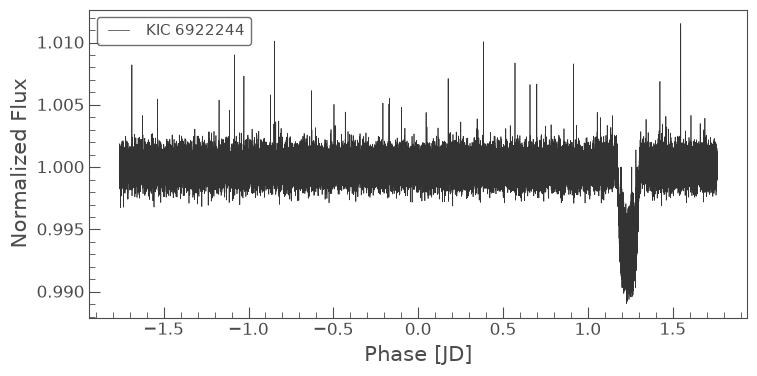

In [12]:
# Here we are folding the light curve on a period of 3.5225 days, which means
# that we are plotting the light curve as a function of phase, where phase is
# defined as the time modulo the period. This is useful for identifying periodic
# signals in the light curve, such as transits or eclipses.
folded_lc = flat_lc.fold(period=3.5225)

# This is how we can remove outliers from the folded light curve.
folded_lc = folded_lc.remove_outliers(sigma=8)

folded_lc.plot()

# Binning

<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

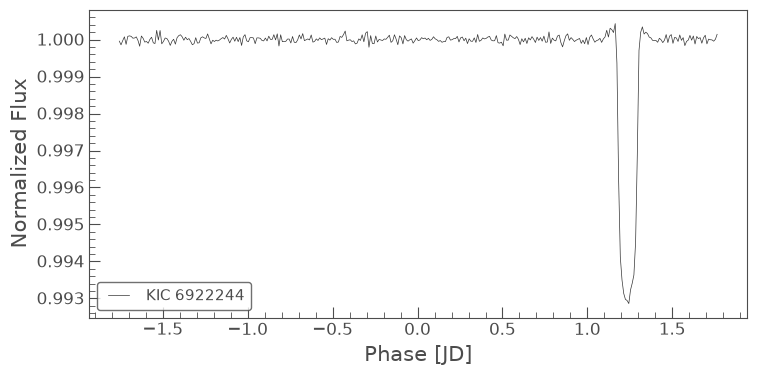

In [13]:
# binning is another way to reduce noise in a light curve besides removing outliers.
# Here we are binning the folded light curve into bins of 0.01 days.
binned_lc  = folded_lc.bin(time_bin_size=0.01) 
binned_lc.plot()


<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

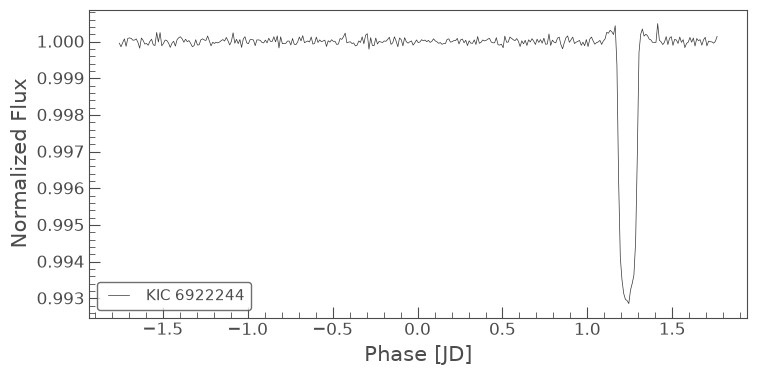

In [14]:
# let's chain a few data transformations together. Here we are removing NaNs, flattening the light curve, folding it on a period of 3.5225 days, and then binning it into bins of 0.01 days.
lc.remove_nans().flatten(window_length=401).fold(period=3.5225).bin(time_bin_size=0.01).plot()

# Periodograms

So, above we used the period 3.5225 to fold the data into one folded lightcurve, and look at a typical "dip" in flux we might associate with an exoplanet transitioning a star. How did we know to use 3.5225? Let's dive into it. This is some great maths and it has applications in a lot of the work I've done before - from detecting heartbeats on an ect, to looking at the speed of propeller blades on a vessel's ampitude-modulated sonar fingerprint.

Let's try calculating a periodigram from scratch (or as near as I'm willing to get lol) so you get the idea, then use the LightKurve Implementation once we've built our confidence up. (This is perhaps a separate notebook)

<Axes: xlabel='Period [$\\mathrm{d}$]', ylabel='BLS Power'>

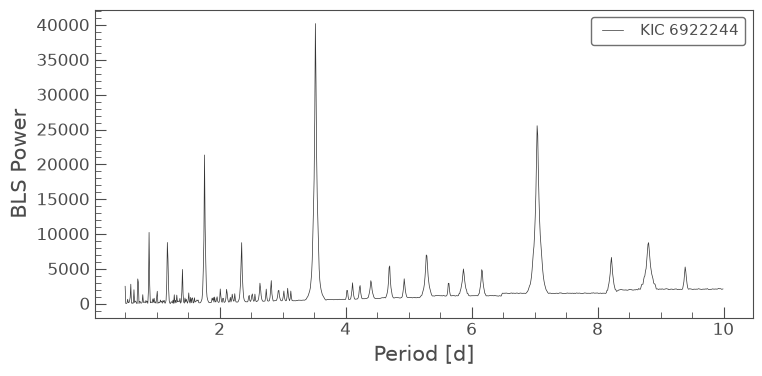

In [16]:
import numpy as np

# here we are using the Box Least Squares (BLS) method to search for periodic signals in the light curve. The BLS method is particularly useful for detecting transiting exoplanets, as it looks for box-shaped dips in the light curve that correspond to a planet passing in front of its host star.
periodogram = flat_lc.to_periodogram(method='bls', period=np.arange(0.5, 10, 0.01))
periodogram.plot()

# Period Fitting

Using the periodigram above, we basically find out where the strongest periodicity occurs. You can see it clearly in the big spike, just above 3.5 on the x-axis. 

In [17]:
best_fit_period = periodogram.period_at_max_power
print("Best-fit period: {:.5f} days".format(best_fit_period ))

Best-fit period: 3.52000 d days


# Identifying Supernovae

<Axes: xlabel='Time - 2454833 [BKJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

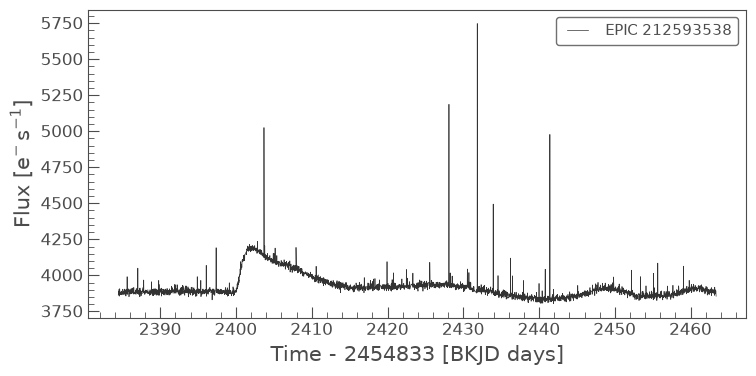

In [18]:
# quality bitmask='hardest' removes data points that are flagged as bad by the TESS pipeline.
# This is important because it ensures that we are only using high-quality data for our analysis.
tpf = search_targetpixelfile('EPIC 212593538', campaign=6).download() # (quality_bitmask='hardest') 
lc = tpf.to_lightcurve(aperture_mask='all')
lc.plot()

In [19]:
import lightkurve as lk
search_result = lk.search_targetpixelfile('Pi Mensae', mission='TESS', sector=1)
tpf = search_result.download(quality_bitmask='default')

c:\Users\mark-\Documents\Repositories\astro-data-lab\.venv\Lib\site-packages\lightkurve\search.py:421: LightkurveWarning: Warning: 2 files available to download. Only the first file has been downloaded. Please use `download_all()` or specify additional criteria (e.g. quarter, campaign, or sector) to limit your search.
  warnings.warn(


In [20]:
tpf.mission
tpf.targetid

261136679

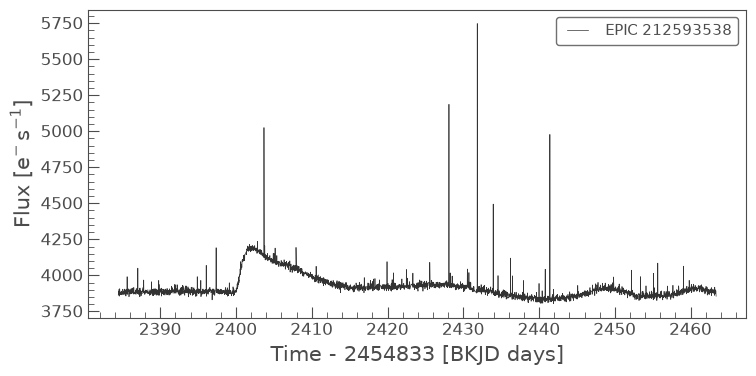

In [22]:
anim_obj = tpf._to_matplotlib_animation(interval=100)
anim_obj.save("tpf_animation.gif", writer="pillow", fps=10)

lc.plot()
anim = tpf.animate(interval=100)  # HTML for inline display
anim